# 06 — Latent market-state discovery around q99

## Research question

Do the observable five-minute market configurations discovered in Modules 03–05 organize themselves into recurrent latent states, and do any **filtered** states or state transitions carry elevated future q99 volatility hazard?

Module 06 introduces the first latent-state model in the Volatility Dynamics branch.

## What is deliberately *not* assumed

- no state is called Mean Reversion, Momentum, VOL, Bridge, Clean or Noisy in advance;
- no duration distribution is imposed beyond the standard HMM geometric implication;
- q99 is not an emission feature and is not used to fit the HMM;
- `return_5m` is used only to construct the external q99 evaluation target;
- no HSMM, transition covariates, shock-bypass gate, or trading layer is introduced yet.

The HMM must first earn the right to exist as a useful statistical representation.


In [1]:
from pathlib import Path
import json, os, sys, warnings
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt
from dotenv import load_dotenv

warnings.filterwarnings('ignore', category=RuntimeWarning)
warnings.filterwarnings('ignore', category=FutureWarning)
pd.set_option('display.max_columns', 200)
pd.set_option('display.width', 320)
pd.set_option('display.max_rows', 300)

load_dotenv()
DATA_ROOT = Path(os.environ['DERIBIT_DATA_ROOT']).expanduser().resolve()
DB_PATH = DATA_ROOT / 'database' / 'research.duckdb'
PROJECT_ROOT = Path.cwd().resolve()
while PROJECT_ROOT != PROJECT_ROOT.parent and not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / 'src' / 'data_engineering').exists():
    raise RuntimeError('Repository root not found.')
SRC = PROJECT_ROOT / 'src'
if str(SRC) not in sys.path:
    sys.path.insert(0, str(SRC))

from data_engineering.modeling import volatility_hmm_states as vh

START = os.getenv('VD6_START', '').strip() or None
END = os.getenv('VD6_END', '').strip() or None
ASSET_FILTER = [x.strip().upper() for x in os.getenv('VD6_ASSETS', '').split(',') if x.strip()]
TRAIN_FRACTION = float(os.getenv('VD6_TRAIN_FRACTION', str(vh.DEFAULT_TRAIN_FRACTION)))
CORE_K = tuple(int(x) for x in os.getenv('VD6_CORE_K', '2,3,4,5').split(',') if x.strip())
L2_K = tuple(int(x) for x in os.getenv('VD6_L2_K', '2,3,4').split(',') if x.strip())
N_INIT_CORE = int(os.getenv('VD6_N_INIT_CORE', str(vh.DEFAULT_N_INIT_CORE)))
N_INIT_L2 = int(os.getenv('VD6_N_INIT_L2', str(vh.DEFAULT_N_INIT_L2)))
MAX_ITER_CORE = int(os.getenv('VD6_MAX_ITER_CORE', str(vh.DEFAULT_MAX_ITER_CORE)))
MAX_ITER_L2 = int(os.getenv('VD6_MAX_ITER_L2', str(vh.DEFAULT_MAX_ITER_L2)))
RUN_L2 = os.getenv('VD6_RUN_L2', '1').strip().lower() not in {'0','false','no'}
OUT = PROJECT_ROOT / 'notebooks' / 'Volatility_Dynamics' / '06'
OUT.mkdir(parents=True, exist_ok=True)

print('Module 06 engine:', vh.VERSION)
print('selftest:', vh.selftest())
print('core K:', CORE_K, '| L2 K:', L2_K, '| RUN_L2:', RUN_L2)


Module 06 engine: 0.1.0
selftest: {'numpy_only_hmm': True, 'baum_welch_fit': True, 'filtered_probabilities_normalized': True, 'state_occupancy_non_degenerate': True}
core K: (2, 3, 4, 5) | L2 K: (2, 3, 4) | RUN_L2: True


## 1. Frozen emission feature contract

The core HMM uses the broad precursor families that had substantial history in Modules 03–05:

\[
X_t=[Range,Volume,TradeCount,ATMIV,Put25IV,Call25IV,Spread,BookUpdates].
\]

The sparse L2 variables are **not** allowed to shorten the main history. They are tested in a separate enhanced model.


In [2]:
con = duckdb.connect(str(DB_PATH), read_only=True)
schema = con.execute('DESCRIBE time_series_feature_state').df()
available = set(schema['column_name'].astype(str))
contract = vh.feature_contract(available)
display(contract)
core_features = [f for f in vh.CORE_FEATURES if f in available]
l2_features = [f for f in vh.L2_FEATURES if f in available]
if len(core_features) != len(vh.CORE_FEATURES):
    raise RuntimeError(f'Missing core features: {set(vh.CORE_FEATURES)-set(core_features)}')
enhanced_features = core_features + l2_features


,feature,model,present,role
0,intrabar_range_bps,core,True,HMM emission
1,volume_usd,core,True,HMM emission
2,trade_count,core,True,HMM emission
3,option_iv_atm_forward,core,True,HMM emission
4,iv_put_25d,core,True,HMM emission
5,iv_call_25d,core,True,HMM emission
6,book_twa_spread_bps,core,True,HMM emission
7,book_update_count,core,True,HMM emission
8,book_obi_20_raw_zero_cross_count,l2_enhanced,True,HMM emission in sparse-L2 enhancement only
9,book_obi_20_transition_count,l2_enhanced,True,HMM emission in sparse-L2 enhancement only


## 2. Load the synchronized five-minute panel

`return_5m` is loaded solely for q99 target construction. It is never placed in the HMM emission matrix.


In [3]:
def qident(name):
    return '"' + str(name).replace('"', '""') + '"'

select_cols = list(dict.fromkeys(['state_time','underlying','return_5m'] + enhanced_features))
where = []
if START:
    ts = pd.Timestamp(START)
    ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
    where.append(f"state_time >= TIMESTAMPTZ '{ts.isoformat()}'")
if END:
    ts = pd.Timestamp(END)
    ts = ts.tz_localize('UTC') if ts.tzinfo is None else ts.tz_convert('UTC')
    end_ts = ts + pd.Timedelta(days=1)
    where.append(f"state_time < TIMESTAMPTZ '{end_ts.isoformat()}'")
if ASSET_FILTER:
    where.append('underlying IN (' + ','.join(repr(x) for x in ASSET_FILTER) + ')')
where_sql = '' if not where else ' WHERE ' + ' AND '.join(where)
sql = (
    'SELECT ' + ', '.join(qident(c) for c in select_cols)
    + ' FROM time_series_feature_state' + where_sql
    + ' ORDER BY underlying, state_time'
)
df = con.execute(sql).df()
con.close()
df['state_time'] = pd.to_datetime(df['state_time'], utc=True)
df = df.reset_index(drop=True)
if df.empty:
    raise RuntimeError('No rows found.')
dupes = int(df.duplicated(['underlying','state_time']).sum())
if dupes:
    raise RuntimeError(f'Found {dupes} duplicate asset/timestamp rows.')
print(f'rows {len(df):,} | assets {sorted(df.underlying.unique())}')
print(df.state_time.min(), '->', df.state_time.max())


rows 38,304 | assets ['AVAX', 'BTC', 'ETH', 'HYPE', 'SOL', 'TRX', 'XRP']
2026-09-19 08:00:00+00:00 -> 2026-10-08 07:55:00+00:00


## 3. Chronological split and training-only normalization

The UTC-date split is fixed before fitting. Exact-clock robust location/scale parameters are estimated **only on the training period**, with each slot shrunk toward its asset-wide training distribution.

This removes much of the deterministic asset/clock scale without allowing test observations to influence the transformation.


In [4]:
split_time = vh.chronological_split_time(df, train_fraction=TRAIN_FRACTION)
normalizer = vh.fit_clock_normalizer(df, enhanced_features, split_time)
zdf = vh.apply_clock_normalizer(df, normalizer, enhanced_features)
print('chronological split:', split_time)
print('train rows:', int((zdf.state_time < split_time).sum()), '| test rows:', int((zdf.state_time >= split_time).sum()))
display(normalizer.source.value_counts().rename_axis('normalizer_source').to_frame('n'))


chronological split: 2026-10-03 00:00:00+00:00
train rows: 27552 | test rows: 10752


,n
normalizer_source,
shrunk_exact_clock,15673
asset_fallback,8519


## 4. Training-only q99 target

For each asset, q99 is estimated from the **training-period** distribution of native five-minute variance:

\[
c_i=Q_{0.99}(r_{i,t}^2\mid t<split).
\]

The frozen threshold is then applied to the test chronology. This target remains completely external to HMM fitting.


In [5]:
q99_thresholds = vh.training_q99_thresholds(df, split_time)
q99_labels = vh.label_q99_onsets_from_train_thresholds(df, q99_thresholds)
display(q99_thresholds)
q99_counts = (
    q99_labels.assign(split=np.where(q99_labels.state_time < split_time, 'train', 'test'))
    .groupby(['split','underlying'])
    .agg(
        q99_bars=('is_q99_train_threshold','sum'),
        q99_onsets=('is_q99_onset_train_threshold','sum'),
        rows=('state_time','size'),
    ).reset_index()
)
display(q99_counts)


,underlying,q99_threshold_train,n_train_finite_returns
0,AVAX,0.000112,3235
1,BTC,0.000017,3235
2,ETH,0.000022,3235
3,HYPE,0.000048,3235
4,SOL,0.000041,3235
5,TRX,0.000003,3233
6,XRP,0.000064,3235


,split,underlying,q99_bars,q99_onsets,rows
0,test,AVAX,5,4,1536
1,test,BTC,4,3,1536
2,test,ETH,6,5,1536
3,test,HYPE,3,3,1536
4,test,SOL,2,2,1536
5,test,TRX,7,7,1536
6,test,XRP,2,1,1536
7,train,AVAX,33,32,3936
8,train,BTC,33,28,3936
9,train,ETH,33,30,3936


## 5. Build exact contiguous core sequences

A sequence ends only when the asset changes, a required core emission is missing, or the timestamp gap is not exactly five minutes. UTC midnight does not reset a crypto state.


In [6]:
core_train, core_train_idx = vh.build_sequences(zdf, core_features, split_time, split='train')
core_test, core_test_idx = vh.build_sequences(zdf, core_features, split_time, split='test')
core_seq_meta = pd.concat([
    vh.sequence_metadata(zdf, core_train_idx, 'train'),
    vh.sequence_metadata(zdf, core_test_idx, 'test'),
], ignore_index=True)
print('core train sequences:', len(core_train), '| rows:', sum(map(len, core_train)))
print('core test sequences:', len(core_test), '| rows:', sum(map(len, core_test)))
display(core_seq_meta.groupby('split').n_rows.describe())


core train sequences: 479 | rows: 13238
core test sequences: 249 | rows: 5719


,count,mean,std,min,25%,50%,75%,max
split,,,,,,,,
test,249.0,22.967871,37.579043,4.0,5.0,10.0,21.0,230.0
train,479.0,27.636743,47.941055,4.0,6.0,10.0,18.5,258.0


## 6. Fit baseline HMM grid

For each candidate (K\in\{2,3,4,5\}), several random initializations are fit with Baum–Welch EM using diagonal Gaussian emissions.

`K` is selected by **training BIC subject to non-degenerate occupancy**. Held-out likelihood is reported but does not choose the state count used for q99 evaluation.


In [7]:
core_compare, core_models = vh.fit_hmm_grid(
    core_train, core_test, CORE_K,
    n_init=N_INIT_CORE,
    max_iter=MAX_ITER_CORE,
    seed_base=6060,
)
core_selected_k = vh.choose_k_by_training_bic(core_compare, min_occupancy=0.01)
core_model = core_models[core_selected_k]
print('selected core K by training BIC:', core_selected_k)
display(core_compare.sort_values('K').round(5))


selected core K by training BIC: 5


,K,n_features,n_train_rows,n_test_rows,n_init,best_seed,best_converged,best_n_iter,train_loglik,train_loglik_per_row,test_loglik,test_loglik_per_row,bic_train,min_train_state_occupancy,max_train_state_occupancy,second_best_train_loglik,best_minus_second_train_loglik,n_converged_initializations
0,2,8,13238,5719,3,6260,True,32,-152937.57313,-11.55292,-89701.47524,-15.68482,306207.32589,0.39634,0.60366,-152940.74293,3.16981,3
1,3,8,13238,5719,3,6361,True,10,-139664.51905,-10.55027,-75917.60509,-13.27463,279860.52552,0.25653,0.47408,-139796.55342,132.03437,3
2,4,8,13238,5719,3,6460,True,13,-132780.95530,-10.03029,-71788.56164,-12.55264,266311.68750,0.18337,0.40885,-132796.27814,15.32283,3
3,5,8,13238,5719,3,6562,True,16,-125156.97723,-9.45437,-69119.98557,-12.08603,251301.00252,0.13313,0.27180,-125257.13946,100.16223,3


## 7. Characterize the discovered core states

The state numbers are arbitrary. Economic labels should be assigned only after inspecting their normalized emission profiles and transition matrix.


In [8]:
core_emissions = vh.state_emission_table(core_model, core_features)
core_transitions = vh.transition_table(core_model)
core_pi = pd.DataFrame({'state': range(core_model.K), 'initial_probability': core_model.pi})
display(core_emissions.pivot(index='state', columns='feature', values='emission_mean_robust_z').round(3))
display(core_transitions.pivot(index='from_state', columns='to_state', values='probability').round(3))


feature,book_twa_spread_bps,book_update_count,intrabar_range_bps,iv_call_25d,iv_put_25d,option_iv_atm_forward,trade_count,volume_usd
state,,,,,,,,
0,0.577,-0.065,0.112,0.503,0.488,0.512,0.121,0.186
1,-0.366,-0.916,-0.516,-1.355,-1.528,-1.489,-0.396,-0.158
2,0.097,0.067,-0.034,-0.267,-0.230,-0.220,0.027,0.093
3,1.748,-0.603,1.296,1.194,1.104,1.228,1.727,1.433
4,-0.143,0.493,0.917,-0.704,-0.726,-0.701,2.162,2.919


to_state,0,1,2,3,4
from_state,,,,,
0,0.889,0.000,0.017,0.091,0.003
1,0.000,0.917,0.004,0.001,0.078
2,0.009,0.004,0.906,0.016,0.066
3,0.148,0.000,0.024,0.817,0.011
4,0.008,0.097,0.139,0.009,0.747


## 8. Held-out filtered state probabilities

Every q99 hazard calculation below uses only **filtered** probabilities:

\[
P(S_t=k\mid X_{1:t}),
\]

never smoothed probabilities that include observations after (t).


In [9]:
core_filtered_test = vh.filtered_state_table(
    zdf, core_model, core_test, core_test_idx, split='test'
)
display(core_filtered_test[['max_filtered_prob','filtered_entropy']].describe())
display(core_filtered_test.hard_state.value_counts(normalize=True).sort_index().rename('test_hard_occupancy').to_frame())


,max_filtered_prob,filtered_entropy
count,5719.000000,5.719000e+03
mean,0.968490,7.559553e-02
std,0.093465,1.876858e-01
min,0.385332,3.691659e-53
25%,0.997588,1.210223e-06
50%,0.999988,1.486923e-04
75%,1.000000,1.714188e-02
max,1.000000,1.175869e+00


,test_hard_occupancy
hard_state,
0,0.008918
1,0.538381
2,0.039867
3,0.066270
4,0.346564


## 9. External q99 hazard by current state

For each held-out timestamp, define whether a q99 onset occurs later within 30, 60, 90 or 120 minutes. The current timestamp itself is excluded.

The soft-state estimate is:

\[
\hat P(q99_{t+h}\mid S_t=k)
=
\frac{\sum_t P(S_t=k\mid X_{1:t})Y_{t,h}}
{\sum_tP(S_t=k\mid X_{1:t})}.
\]


In [10]:
core_state_hazard = vh.state_q99_hazard(zdf, core_filtered_test, q99_labels)
display(core_state_hazard.sort_values(['horizon_min','soft_hazard_lift'], ascending=[True,False]).round(4))


,horizon_min,state,baseline_hazard,soft_state_hazard,soft_hazard_lift,hard_state_hazard,hard_hazard_lift,hard_state_n,soft_state_weight
3,30,3,0.0150,0.0569,3.7852,0.0554,3.6847,379,380.6407
2,30,2,0.0150,0.0276,1.8333,0.0219,1.4583,228,230.0636
4,30,4,0.0150,0.0179,1.1929,0.0187,1.2414,1982,2005.1247
1,30,1,0.0150,0.0071,0.4732,0.0075,0.4968,3079,3055.6497
0,30,0,0.0150,0.0059,0.3896,0.0000,0.0000,51,47.5213
8,60,3,0.0297,0.1025,3.4480,0.1003,3.3730,379,380.6407
7,60,2,0.0297,0.0560,1.8830,0.0526,1.7706,228,230.0636
9,60,4,0.0297,0.0347,1.1678,0.0348,1.1712,1982,2005.1247
6,60,1,0.0297,0.0158,0.5309,0.0166,0.5572,3079,3055.6497
5,60,0,0.0297,0.0059,0.1974,0.0000,0.0000,51,47.5213


## 10. Does a state transition matter more than the state itself?

Hard filtered transitions are evaluated only across exact contiguous five-minute observations. Rare transitions must not be overinterpreted.


In [11]:
core_transition_hazard = vh.transition_q99_hazard(zdf, core_filtered_test, q99_labels)
display(
    core_transition_hazard[core_transition_hazard.n_transitions >= 20]
    .sort_values(['horizon_min','hazard_lift'], ascending=[True,False])
    .head(80).round(4)
)


,horizon_min,from_state,to_state,n_transitions,baseline_hazard,transition_hazard,hazard_lift
16,30,3,4,20,0.0155,0.1000,6.4353
15,30,3,3,332,0.0155,0.0572,3.6828
10,30,2,2,156,0.0155,0.0256,1.6501
7,30,1,4,346,0.0155,0.0231,1.4879
11,30,2,4,47,0.0155,0.0213,1.3692
19,30,4,2,55,0.0155,0.0182,1.1701
21,30,4,4,1504,0.0155,0.0173,1.1125
18,30,4,1,349,0.0155,0.0143,0.9220
4,30,1,1,2543,0.0155,0.0067,0.4302
0,30,0,0,38,0.0155,0.0000,0.0000


## 11. Event-align the filtered states around held-out q99 onsets

This asks whether the −95m motif was the average footprint of a latent state transition. Simultaneous multi-asset q99 events are collapsed by timestamp before the pooled profile.


,rel_bar,rel_min,p_state_0_mean,p_state_0_median,p_state_1_mean,p_state_1_median,p_state_2_mean,p_state_2_median,p_state_3_mean,p_state_3_median,p_state_4_mean,p_state_4_median,n_unique_event_times
0,-24,-120,3.538266e-13,2.785880e-15,3.099922e-01,1.679534e-01,1.527176e-03,6.841726e-06,0.044657,9.676734e-07,0.643823,0.829405,8
1,-23,-115,1.705464e-10,3.433692e-15,2.596571e-01,8.264723e-02,4.463637e-03,5.794297e-06,0.044013,7.509775e-07,0.691866,0.906447,8
2,-22,-110,1.435558e-08,1.716449e-14,4.849021e-01,4.459954e-01,4.428351e-02,1.958279e-05,0.049658,1.990823e-06,0.421156,0.341089,8
3,-21,-105,1.131981e-08,6.939619e-16,3.723661e-01,3.744408e-01,3.895063e-02,5.854421e-06,0.141772,2.073539e-06,0.446911,0.354009,8
4,-20,-100,1.293092e-11,5.932028e-20,3.855598e-01,2.495912e-01,2.946925e-02,9.152683e-09,0.183419,4.690877e-07,0.401552,0.091158,8
5,-19,-95,2.501894e-10,3.814231e-16,2.235300e-01,7.525389e-02,3.208408e-04,1.075101e-06,0.184649,1.145850e-06,0.591500,0.872618,8
6,-18,-90,1.385984e-11,1.527426e-17,2.875341e-01,1.984264e-01,5.368136e-03,3.884768e-07,0.092809,5.884412e-07,0.614289,0.801551,8
7,-17,-85,7.470869e-12,3.329879e-18,3.454180e-01,2.500482e-01,7.241512e-06,1.035921e-09,0.071441,7.822286e-07,0.583134,0.749893,7
8,-16,-80,1.001175e-08,2.713360e-17,5.184177e-01,4.907585e-01,3.327893e-02,2.278646e-06,0.062502,3.093702e-06,0.385801,0.287066,8
9,-15,-75,2.081118e-13,1.625308e-15,5.397568e-01,6.465801e-01,2.339990e-04,4.192868e-08,0.062753,3.924831e-06,0.397256,0.262736,8


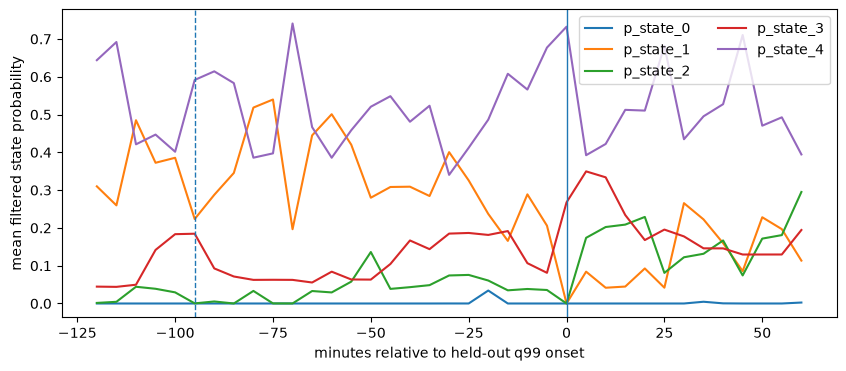

In [12]:
core_alignment = vh.event_aligned_state_probabilities(
    zdf, core_filtered_test, q99_labels,
    split_time=split_time,
    rel_bars=range(-24,13),
)
display(core_alignment)
prob_mean_cols = [c for c in core_alignment.columns if c.startswith('p_state_') and c.endswith('_mean')]
if len(core_alignment):
    fig, ax = plt.subplots(figsize=(10,4))
    for c in prob_mean_cols:
        ax.plot(core_alignment.rel_min, core_alignment[c], label=c.replace('_mean',''))
    ax.axvline(-95, linestyle='--', linewidth=1)
    ax.axvline(0, linewidth=1)
    ax.set_xlabel('minutes relative to held-out q99 onset')
    ax.set_ylabel('mean filtered state probability')
    ax.legend(ncol=2)
    plt.show()


## 12. Does the HMM duration assumption look credible?

A standard HMM implies geometric state duration with constant exit probability:

\[
h_k=1-A_{kk}.
\]

We compare this with empirical durations of hard **filtered** test-state runs. Material age dependence or systematic duration mismatch would be evidence for testing an HSMM next.


,state,n_uncensored_runs,empirical_mean_duration_bars,empirical_median_duration_bars,empirical_q90_duration_bars,hmm_self_transition,geometric_implied_mean_duration_bars,mean_duration_ratio_empirical_to_geometric
0,0,11,4.455,2.0,9.0,0.889,8.989,0.496
1,1,286,4.881,2.0,11.0,0.917,12.063,0.405
2,2,52,3.096,2.0,7.8,0.906,10.632,0.291
3,3,33,6.545,1.0,7.4,0.817,5.454,1.200
4,4,384,2.906,1.0,5.0,0.747,3.948,0.736


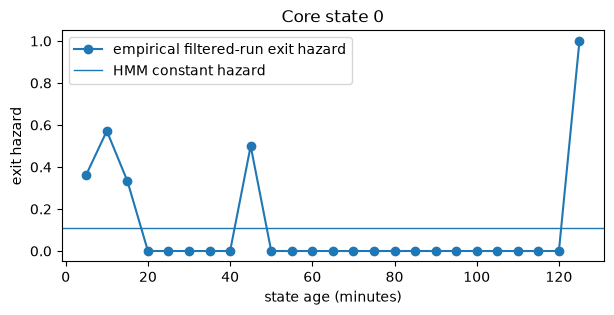

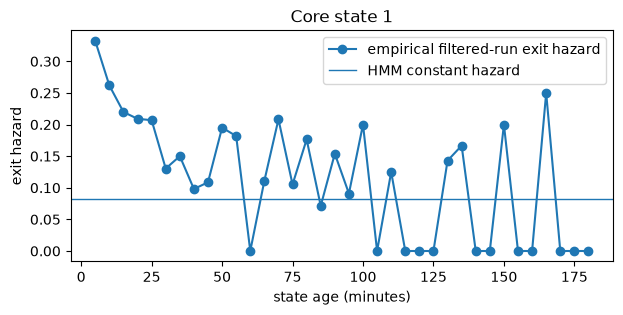

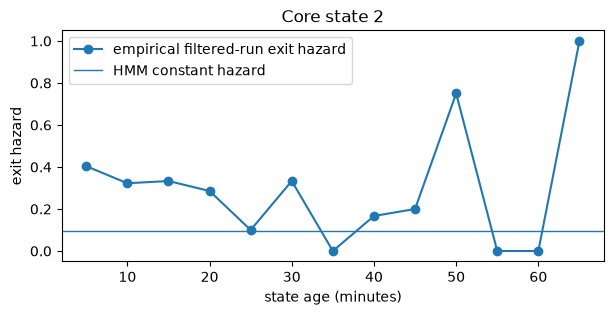

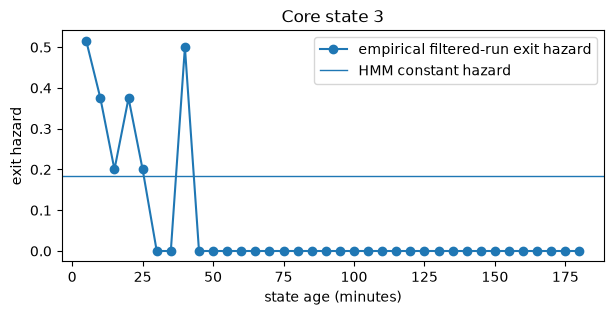

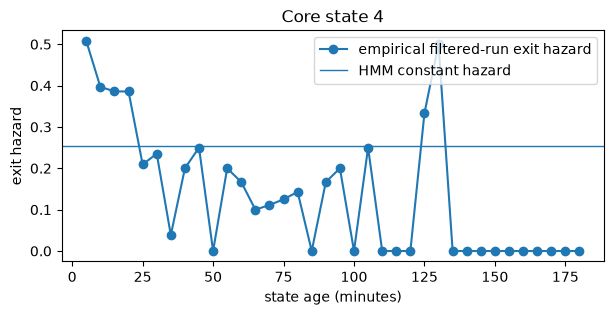

In [13]:
core_duration_summary, core_duration_hazard = vh.duration_diagnostics(core_model, core_filtered_test)
display(core_duration_summary.round(3))
for k in range(core_model.K):
    g = core_duration_hazard[core_duration_hazard.state == k]
    if not len(g):
        continue
    fig, ax = plt.subplots(figsize=(7,3))
    ax.plot(g.age_min, g.empirical_exit_hazard, marker='o', label='empirical filtered-run exit hazard')
    ax.axhline(float(g.hmm_constant_exit_hazard.iloc[0]), linewidth=1, label='HMM constant hazard')
    ax.set_title(f'Core state {k}')
    ax.set_xlabel('state age (minutes)')
    ax.set_ylabel('exit hazard')
    ax.legend()
    plt.show()


## 13. Separate sparse-L2 enhancement

The L2 variables are central to the −95m motif but cover much less history. They are therefore added only in a separate model using complete cases for the combined core+L2 feature vector.

This model is exploratory and should not replace the broad-history core HMM unless its states are stable and informative.


In [14]:
l2_compare = pd.DataFrame()
l2_emissions = pd.DataFrame()
l2_transitions = pd.DataFrame()
l2_pi = pd.DataFrame()
l2_filtered_test = pd.DataFrame()
l2_state_hazard = pd.DataFrame()
l2_transition_hazard = pd.DataFrame()
l2_alignment = pd.DataFrame()
l2_duration_summary = pd.DataFrame()
l2_duration_hazard = pd.DataFrame()
l2_seq_meta = pd.DataFrame()
l2_selected_k = None

if RUN_L2 and len(l2_features) == len(vh.L2_FEATURES):
    l2_train, l2_train_idx = vh.build_sequences(zdf, enhanced_features, split_time, split='train')
    l2_test, l2_test_idx = vh.build_sequences(zdf, enhanced_features, split_time, split='test')
    l2_seq_meta = pd.concat([
        vh.sequence_metadata(zdf, l2_train_idx, 'train'),
        vh.sequence_metadata(zdf, l2_test_idx, 'test'),
    ], ignore_index=True)
    print('L2-enhanced train rows:', sum(map(len,l2_train)), '| test rows:', sum(map(len,l2_test)))
    if len(l2_train) and len(l2_test):
        l2_compare, l2_models = vh.fit_hmm_grid(
            l2_train, l2_test, L2_K,
            n_init=N_INIT_L2,
            max_iter=MAX_ITER_L2,
            seed_base=6600,
        )
        l2_selected_k = vh.choose_k_by_training_bic(l2_compare, min_occupancy=0.01)
        l2_model = l2_models[l2_selected_k]
        print('selected L2-enhanced K by training BIC:', l2_selected_k)
        display(l2_compare.round(5))
        l2_emissions = vh.state_emission_table(l2_model, enhanced_features)
        l2_transitions = vh.transition_table(l2_model)
        l2_pi = pd.DataFrame({'state':range(l2_model.K),'initial_probability':l2_model.pi})
        l2_filtered_test = vh.filtered_state_table(zdf, l2_model, l2_test, l2_test_idx, split='test')
        l2_state_hazard = vh.state_q99_hazard(zdf, l2_filtered_test, q99_labels)
        l2_transition_hazard = vh.transition_q99_hazard(zdf, l2_filtered_test, q99_labels)
        l2_alignment = vh.event_aligned_state_probabilities(zdf, l2_filtered_test, q99_labels, split_time=split_time, rel_bars=range(-24,13))
        l2_duration_summary, l2_duration_hazard = vh.duration_diagnostics(l2_model, l2_filtered_test)
        display(l2_emissions.pivot(index='state', columns='feature', values='emission_mean_robust_z').round(3))
        display(l2_state_hazard.sort_values(['horizon_min','soft_hazard_lift'], ascending=[True,False]).round(4))


L2-enhanced train rows: 2248 | test rows: 5719
selected L2-enhanced K by training BIC: 4


,K,n_features,n_train_rows,n_test_rows,n_init,best_seed,best_converged,best_n_iter,train_loglik,train_loglik_per_row,test_loglik,test_loglik_per_row,bic_train,min_train_state_occupancy,max_train_state_occupancy,second_best_train_loglik,best_minus_second_train_loglik,n_converged_initializations
0,2,12,2248,5719,2,6800,True,22,-36210.02741,-16.10766,-129217.29506,-22.59439,72813.66242,0.45175,0.54825,-36973.53173,763.50432,2
1,3,12,2248,5719,2,6900,True,15,-33569.79386,-14.93318,-123894.33238,-21.66364,67757.01141,0.21528,0.49538,-34025.04922,455.25536,2
2,4,12,2248,5719,2,7000,True,14,-31843.65382,-14.16533,-123938.28470,-21.67132,64543.98301,0.15784,0.37787,-32090.51762,246.86381,2


feature,book_obi_20_path_roughness_per_min,book_obi_20_raw_zero_cross_count,book_obi_20_raw_zero_cross_rate,book_obi_20_transition_count,book_twa_spread_bps,book_update_count,intrabar_range_bps,iv_call_25d,iv_put_25d,option_iv_atm_forward,trade_count,volume_usd
state,,,,,,,,,,,,
0,1.322,0.893,0.719,-0.177,0.411,0.828,1.746,-0.296,-0.238,-0.226,3.428,4.040
1,-0.228,-0.161,-0.162,-0.167,-0.451,0.317,0.103,0.126,-0.012,0.070,0.661,1.029
2,-0.851,-0.753,-0.755,-1.438,-0.616,-0.413,-0.490,-1.019,-1.062,-1.098,-0.093,0.637
3,0.571,0.611,0.593,0.282,-0.364,0.686,0.250,-0.940,-1.023,-0.957,1.031,1.874


,horizon_min,state,baseline_hazard,soft_state_hazard,soft_hazard_lift,hard_state_hazard,hard_hazard_lift,hard_state_n,soft_state_weight
0,30,0,0.0150,0.0303,2.0140,0.0305,2.0290,1606,1616.0200
1,30,1,0.0150,0.0160,1.0642,0.0168,1.1176,238,237.4711
3,30,3,0.0150,0.0150,0.9991,0.0151,1.0011,1860,1863.3664
2,30,2,0.0150,0.0026,0.1748,0.0025,0.1650,2015,2002.1424
4,60,0,0.0297,0.0561,1.8859,0.0560,1.8852,1606,1616.0200
7,60,3,0.0297,0.0290,0.9755,0.0290,0.9767,1860,1863.3664
5,60,1,0.0297,0.0272,0.9145,0.0294,0.9894,238,237.4711
6,60,2,0.0297,0.0094,0.3179,0.0094,0.3172,2015,2002.1424
8,90,0,0.0439,0.0685,1.5619,0.0685,1.5606,1606,1616.0200
9,90,1,0.0439,0.0549,1.2516,0.0588,1.3403,238,237.4711


## 14. Persist compact outputs


In [15]:
contract.to_csv(OUT / '06_feature_contract.csv', index=False)
normalizer.to_csv(OUT / '06_clock_normalizer_params.csv', index=False)
q99_thresholds.to_csv(OUT / '06_q99_train_thresholds.csv', index=False)
q99_counts.to_csv(OUT / '06_q99_counts.csv', index=False)
core_seq_meta.to_csv(OUT / '06_core_sequence_metadata.csv', index=False)
core_compare.to_csv(OUT / '06_core_model_comparison.csv', index=False)
core_pi.to_csv(OUT / '06_core_initial_probabilities.csv', index=False)
core_emissions.to_csv(OUT / '06_core_emissions.csv', index=False)
core_transitions.to_csv(OUT / '06_core_transitions.csv', index=False)
core_filtered_test.to_csv(OUT / '06_core_filtered_test.csv', index=False)
core_state_hazard.to_csv(OUT / '06_core_state_q99_hazard.csv', index=False)
core_transition_hazard.to_csv(OUT / '06_core_transition_q99_hazard.csv', index=False)
core_alignment.to_csv(OUT / '06_core_q99_alignment.csv', index=False)
core_duration_summary.to_csv(OUT / '06_core_duration_summary.csv', index=False)
core_duration_hazard.to_csv(OUT / '06_core_duration_hazard.csv', index=False)

if len(l2_compare):
    l2_seq_meta.to_csv(OUT / '06_l2_sequence_metadata.csv', index=False)
    l2_compare.to_csv(OUT / '06_l2_model_comparison.csv', index=False)
    l2_pi.to_csv(OUT / '06_l2_initial_probabilities.csv', index=False)
    l2_emissions.to_csv(OUT / '06_l2_emissions.csv', index=False)
    l2_transitions.to_csv(OUT / '06_l2_transitions.csv', index=False)
    l2_filtered_test.to_csv(OUT / '06_l2_filtered_test.csv', index=False)
    l2_state_hazard.to_csv(OUT / '06_l2_state_q99_hazard.csv', index=False)
    l2_transition_hazard.to_csv(OUT / '06_l2_transition_q99_hazard.csv', index=False)
    l2_alignment.to_csv(OUT / '06_l2_q99_alignment.csv', index=False)
    l2_duration_summary.to_csv(OUT / '06_l2_duration_summary.csv', index=False)
    l2_duration_hazard.to_csv(OUT / '06_l2_duration_hazard.csv', index=False)

meta = {
    'version': vh.VERSION,
    'module': '06_latent_market_state_hmm',
    'model_class': 'first-order diagonal-Gaussian HMM',
    'numpy_only_implementation': True,
    'q99_used_in_fit': False,
    'return_5m_used_as_emission': False,
    'state_labels_forced': False,
    'duration_model': 'standard HMM geometric implication only',
    'train_fraction_by_utc_date': TRAIN_FRACTION,
    'split_time': str(split_time),
    'normalization': 'training-only asset/exact-clock robust z with shrinkage',
    'core_features': core_features,
    'l2_features': l2_features,
    'core_candidate_K': list(CORE_K),
    'core_selected_K_training_BIC': int(core_selected_k),
    'l2_candidate_K': list(L2_K),
    'l2_selected_K_training_BIC': int(l2_selected_k) if l2_selected_k is not None else None,
    'future_q99_horizons_min': list(vh.DEFAULT_FUTURE_HORIZONS_MIN),
    'heldout_hazard_uses_filtered_states_only': True,
    'smoothing_used_for_heldout_decisions': False,
    'hsmm_not_fit': True,
    'start': START or 'earliest_available',
    'end': END or 'latest_available',
    'n_rows': int(len(df)),
}
(OUT / '06_run_metadata.json').write_text(json.dumps(meta, indent=2))
print('wrote Module 06 outputs to', OUT)


wrote Module 06 outputs to D:\Projects\deribit_market_data\notebooks\Volatility_Dynamics\06


## Interpretation boundary

Module 06 can establish that recurrent hidden configurations exist, characterize them, and test whether their **held-out filtered probabilities** are associated with future q99 hazard.

It does not yet establish an HSMM, a Bridge state, or a trading signal. An HSMM is justified only if state-age/duration diagnostics show that the HMM's constant exit hazard is materially inadequate and the richer duration model subsequently improves chronological out-of-sample performance.
